# Burnout Level Classification

Same data cleaning and preprocessing as the regression model (`preprocessing.py`). Only the target (`burnout_level`) and the models are different.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from scipy.stats import loguniform

from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

from preprocessing import DROP_COLS, SEED, build_preprocessor, load_data

## Load data

Same columns are dropped as in the regression model. `burnout_score` is also dropped here because `burnout_level` is made directly from it.

In [2]:
df = load_data()

TARGET = "burnout_level"
X = df.drop(columns=DROP_COLS + ["burnout_score"])
y = df[TARGET]

print(X.shape)
y.value_counts(normalize=True).round(3)

(100000, 27)


burnout_level
Severe      0.286
Moderate    0.263
Low         0.258
High        0.194
Name: proportion, dtype: float64

## Train/test split

Same split as the regression model (80/20, stratified on `burnout_score` deciles, same seed), so both models are trained and tested on exactly the same employees.

In [3]:
score_bins = pd.qcut(df["burnout_score"], q=10, labels=False, duplicates="drop")
X_train, X_test, y_train, y_test, score_train, score_test = train_test_split(
    X, y, df["burnout_score"], test_size=0.2, random_state=SEED, stratify=score_bins
)

print("train:", X_train.shape, " test:", X_test.shape)
pd.DataFrame({"train": y_train.value_counts(normalize=True),
              "test": y_test.value_counts(normalize=True)}).round(3)

train: (80000, 27)  test: (20000, 27)


,train,test
burnout_level,,
Severe,0.286,0.286
Moderate,0.262,0.265
Low,0.258,0.256
High,0.194,0.192


In [4]:
train_bins = pd.qcut(score_train, q=10, labels=False, duplicates="drop")
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train, train_bins))

## Preprocessing pipeline

Logic fixes → median imputation + scaling for numeric columns, most-frequent imputation + one-hot encoding for categorical columns.

In [5]:
def make_model(estimator):
    return Pipeline([("prep", build_preprocessor(X_train)), ("model", estimator)])

prep = build_preprocessor(X_train).fit(X_train)
ct = prep.named_steps["columns"]
print("1. fix: logic rules (fix_logic)")
print("2. gender: missing or unknown gender -> Prefer not to say (clean_gender)")
for i, (name, pipe, cols) in enumerate(ct.transformers_[:2], start=3):
    steps = " -> ".join(type(step).__name__ for _, step in pipe.steps)
    print(f"{i}. {name} ({len(cols)} columns): {steps}")

1. fix: logic rules (fix_logic)
2. gender: missing or unknown gender -> Prefer not to say (clean_gender)
3. num (20 columns): SimpleImputer -> StandardScaler
4. cat (7 columns): SimpleImputer -> OneHotEncoder


## Model comparison (5-fold CV on train)

In [6]:
models = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "Naive Bayes": GaussianNB(),
    "Logistic Regression": LogisticRegression(max_iter=2000),
}
scoring = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]

results = []
for name, est in models.items():
    s = cross_validate(make_model(est), X_train, y_train, cv=cv,
                       scoring=scoring, return_train_score=True)
    results.append({
        "model": name,
        "accuracy": s["test_accuracy"].mean(),
        "precision": s["test_precision_macro"].mean(),
        "recall": s["test_recall_macro"].mean(),
        "f1_macro": s["test_f1_macro"].mean(),
        "f1_std": s["test_f1_macro"].std(),
        "train_accuracy": s["train_accuracy"].mean(),
    })

results = pd.DataFrame(results).set_index("model").sort_values("f1_macro", ascending=False)
results.round(4)

,accuracy,precision,recall,f1_macro,f1_std,train_accuracy
model,,,,,,
Logistic Regression,0.7073,0.6886,0.6867,0.6865,0.0030,0.7090
Decision Tree,0.5763,0.5605,0.5593,0.5598,0.0016,1.0000
Naive Bayes,0.5680,0.5285,0.5434,0.5296,0.0035,0.5717
Dummy (most frequent),0.2856,0.0714,0.2500,0.1111,0.0002,0.2856


Logistic Regression is clearly the best. The decision tree overfits (100% train accuracy), and Naive Bayes is held back by its independence assumption. We tune Logistic Regression.

## Hyperparameter tuning

In [7]:
param_dist = {
    "model__C": loguniform(1e-3, 100),
    "model__class_weight": [None, "balanced"],
}
search = RandomizedSearchCV(make_model(LogisticRegression(max_iter=2000)), param_dist,
                            n_iter=20, cv=cv, scoring="f1_macro",
                            random_state=SEED, n_jobs=-1)
search.fit(X_train, y_train)

print("best params:", search.best_params_)
print("best CV macro F1:", round(search.best_score_, 4))
best_model = search.best_estimator_

best params: {'model__C': np.float64(3.4702669886504163), 'model__class_weight': 'balanced'}
best CV macro F1: 0.6946


## Final evaluation on the test set

In [8]:
def evaluate(name, pred):
    return {"model": name,
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred, average="macro", zero_division=0),
            "recall": recall_score(y_test, pred, average="macro", zero_division=0),
            "f1_macro": f1_score(y_test, pred, average="macro")}

test_results = [
    evaluate(name, make_model(models[name]).fit(X_train, y_train).predict(X_test))
    for name in ["Dummy (most frequent)", "Decision Tree", "Naive Bayes"]
]
y_pred = best_model.predict(X_test)
test_results.append(evaluate("Logistic Regression (tuned)", y_pred))

pd.DataFrame(test_results).set_index("model").round(4)

,accuracy,precision,recall,f1_macro
model,,,,
Dummy (most frequent),0.2862,0.0716,0.2500,0.1113
Decision Tree,0.5814,0.5656,0.5654,0.5654
Naive Bayes,0.5766,0.5356,0.5518,0.5369
Logistic Regression (tuned),0.7100,0.7027,0.7008,0.7001


In [9]:
labels = ["Low", "Moderate", "High", "Severe"]
print(classification_report(y_test, y_pred, labels=labels, digits=3))

              precision    recall  f1-score   support

         Low      0.833     0.813     0.823      5129
    Moderate      0.636     0.589     0.612      5306
        High      0.490     0.592     0.536      3840
      Severe      0.852     0.809     0.830      5725

    accuracy                          0.710     20000
   macro avg      0.703     0.701     0.700     20000
weighted avg      0.720     0.710     0.714     20000



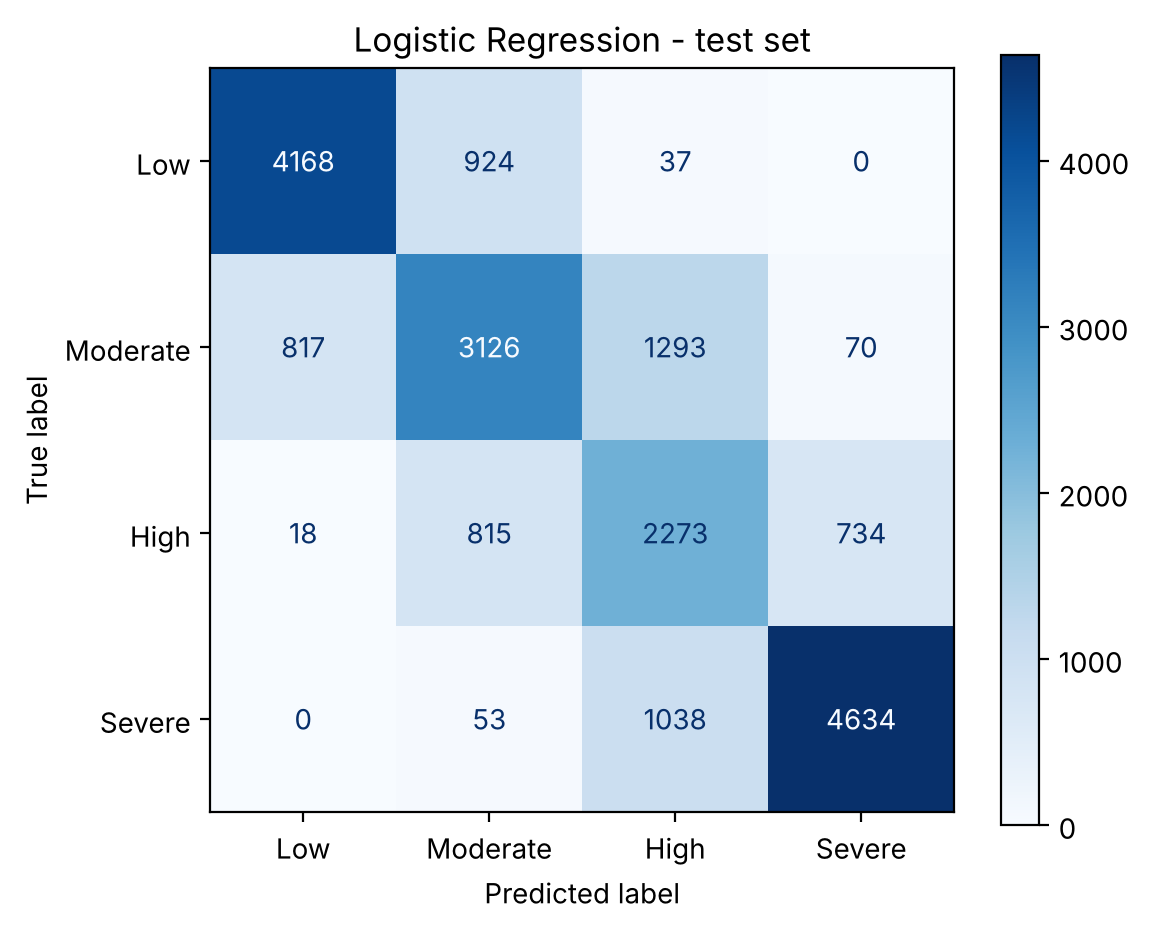

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=labels, cmap="Blues", ax=ax)
ax.set_title("Logistic Regression - test set")
plt.show()

Most mistakes are between neighbouring levels (e.g. Moderate vs High), which makes sense since the levels are cut-offs on the same score.

## SHAP

SHAP values on the preprocessed features (scaled numeric + one-hot), using a sample of the test set.

In [11]:
prep = best_model.named_steps["prep"]
clf = best_model.named_steps["model"]

feature_names = [n.split("__", 1)[1] for n in prep.named_steps["columns"].get_feature_names_out()]
background = prep.transform(X_train.sample(100, random_state=SEED))
X_test_t = pd.DataFrame(prep.transform(X_test.sample(2000, random_state=SEED)), columns=feature_names)

explainer = shap.LinearExplainer(clf, background)
sv = explainer(X_test_t)
print(sv.shape, "classes:", list(clf.classes_))

(2000, 69, 4) classes: ['High', 'Low', 'Moderate', 'Severe']


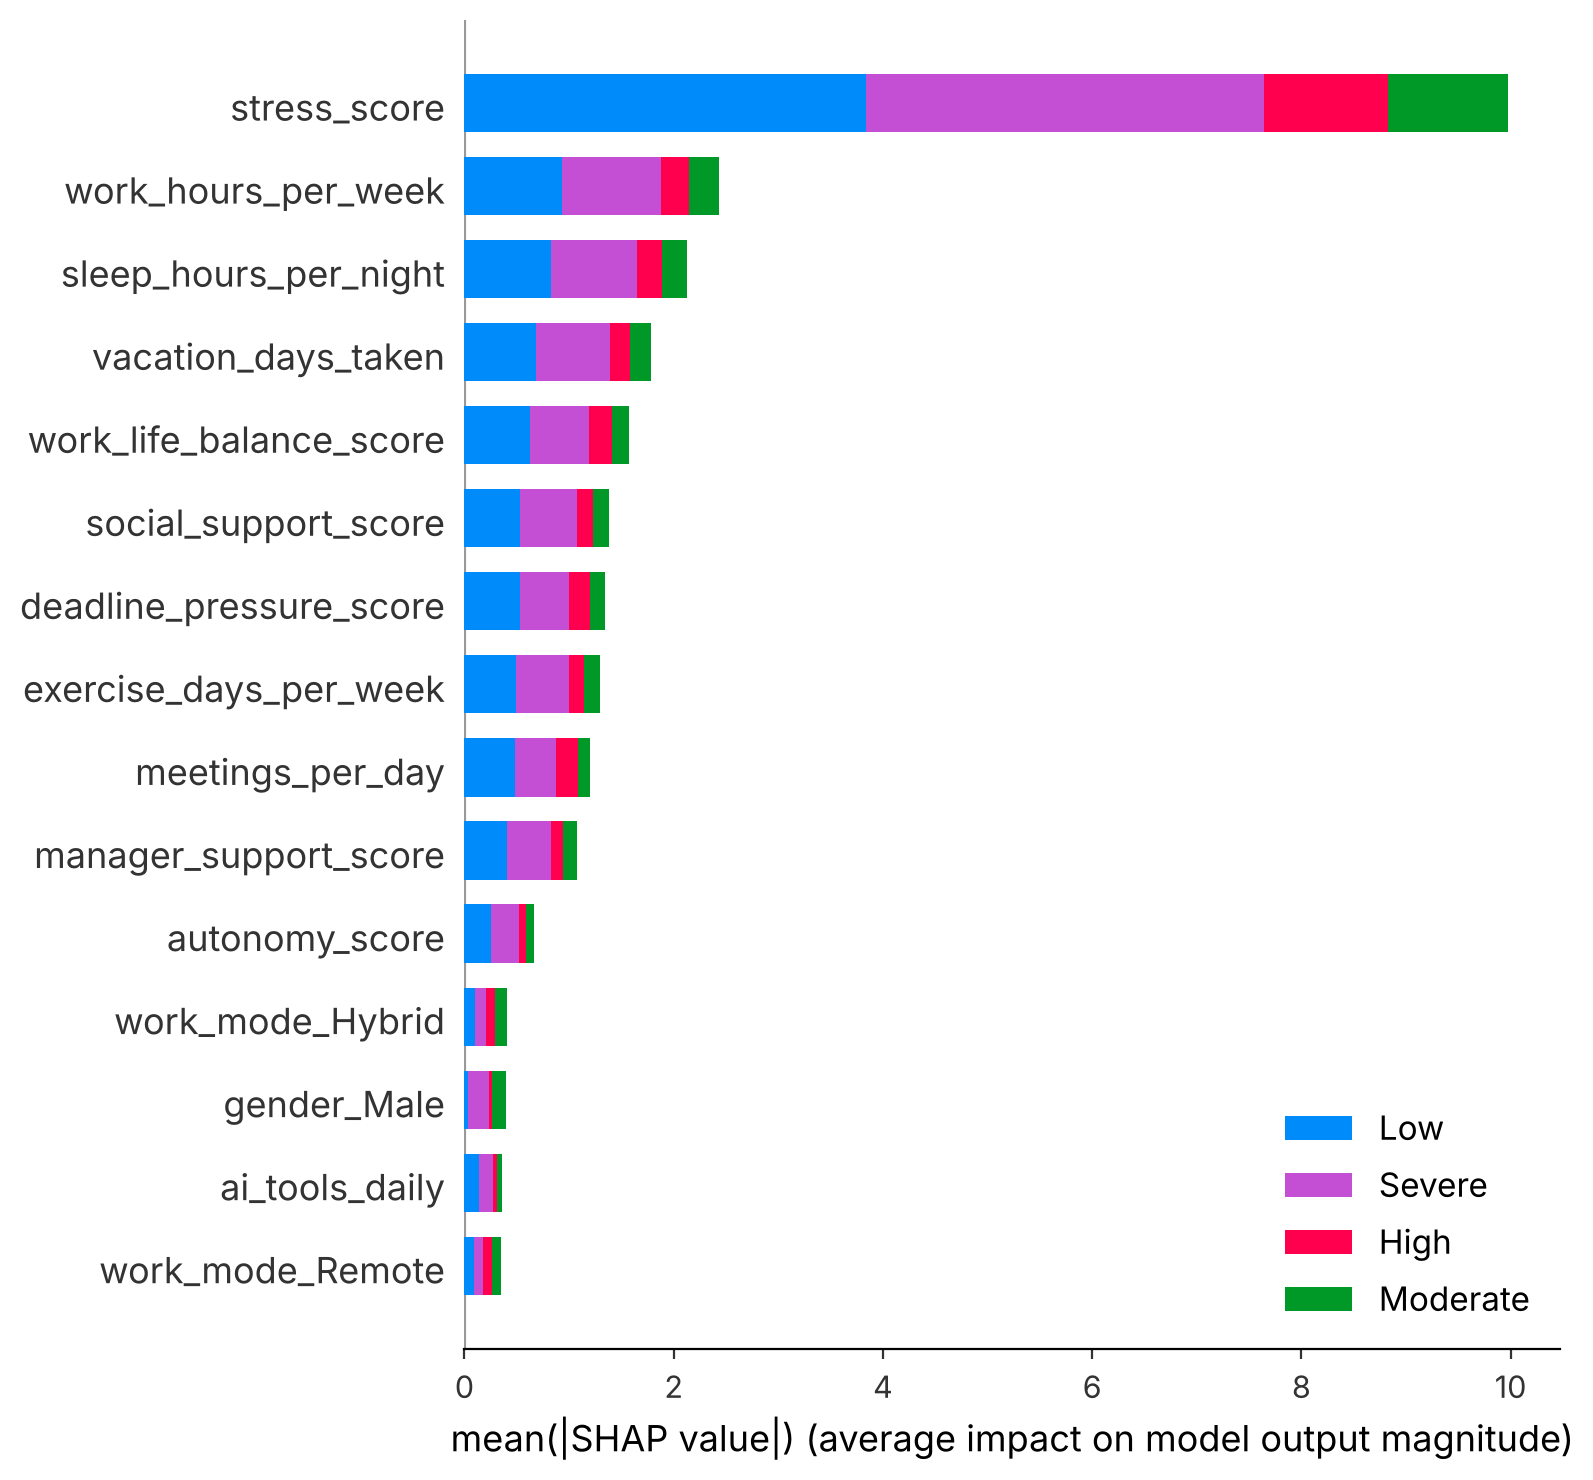

In [12]:
shap.summary_plot([sv.values[:, :, i] for i in range(len(clf.classes_))], X_test_t,
                  plot_type="bar", class_names=list(clf.classes_), max_display=15)

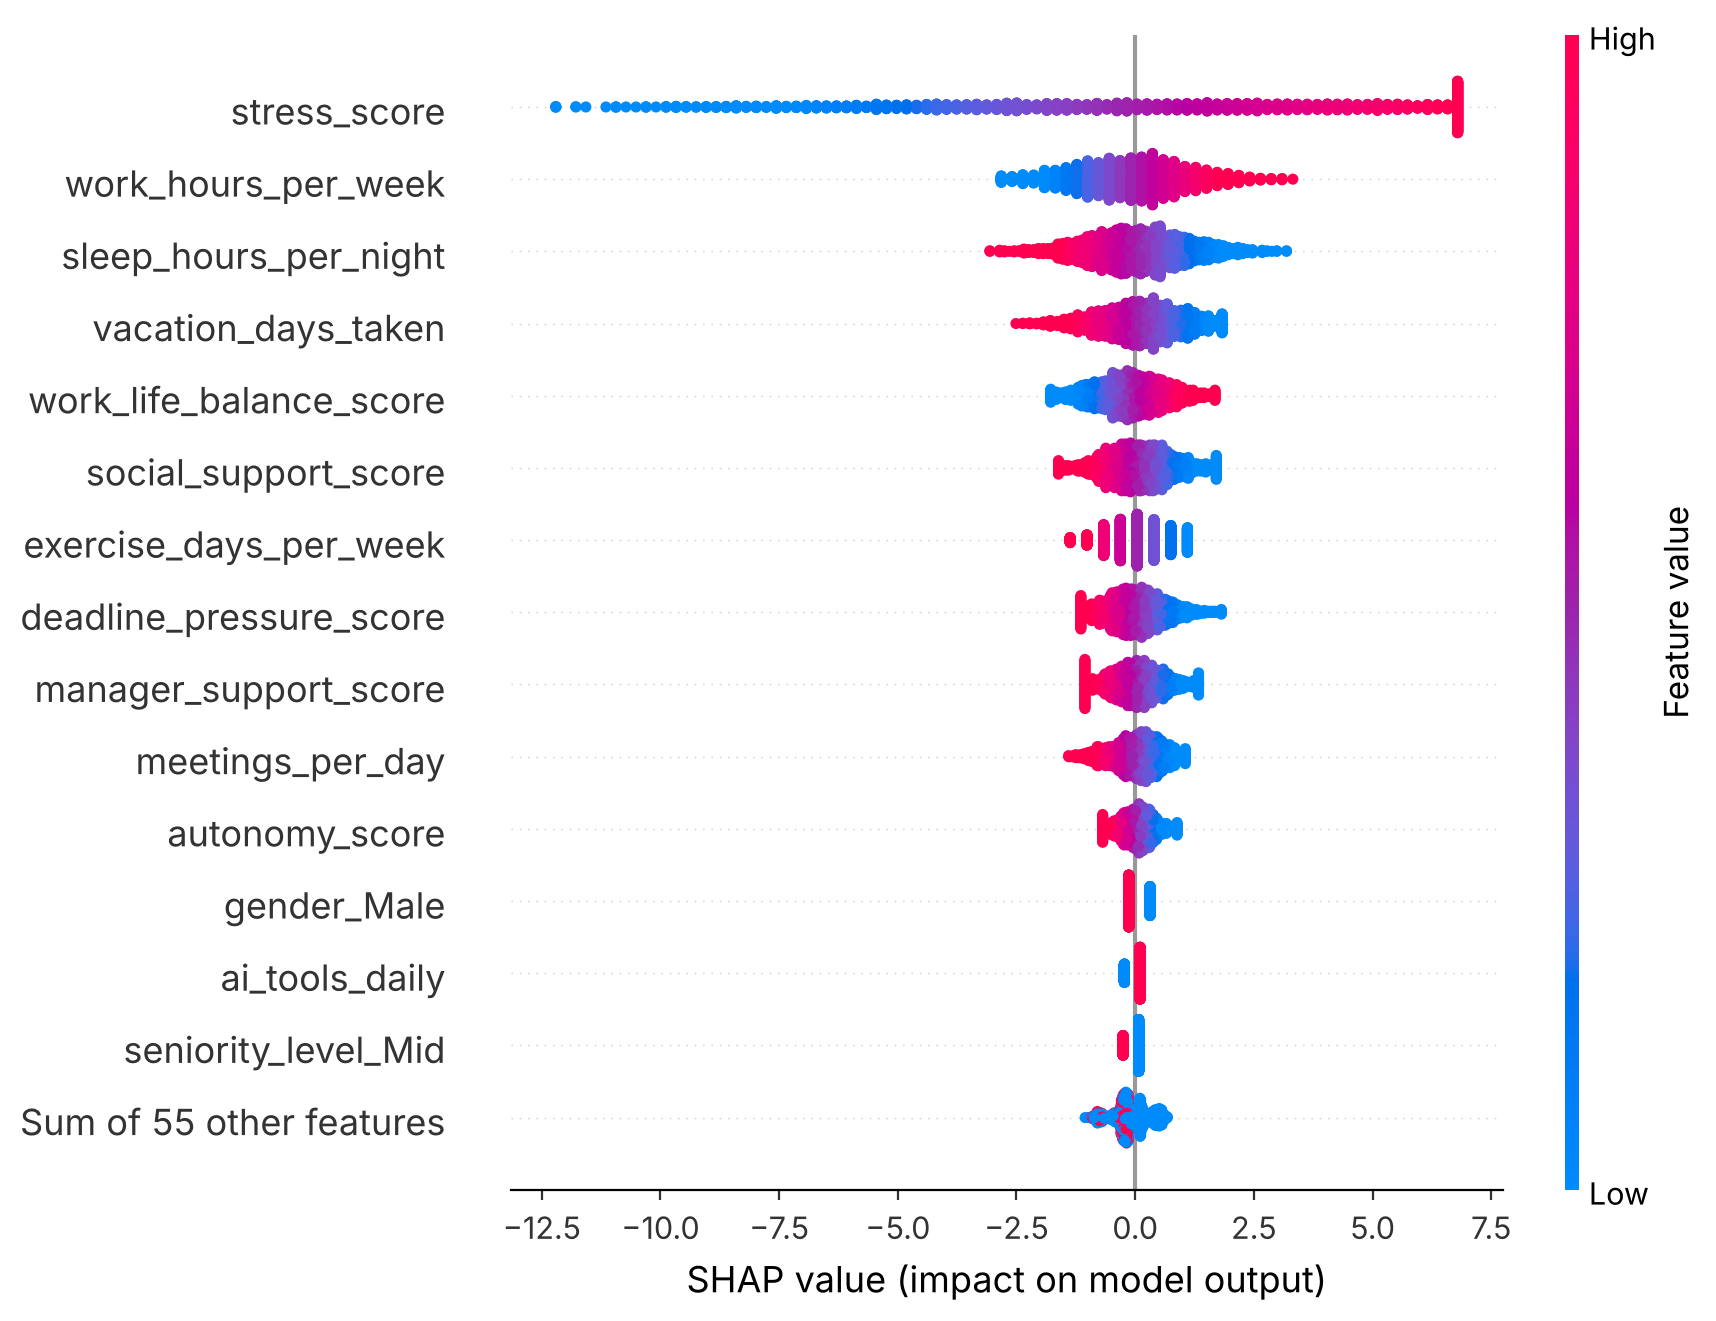

In [13]:
severe = list(clf.classes_).index("Severe")
shap.plots.beeswarm(sv[:, :, severe], max_display=15)

For the Severe class, high stress and long working hours push predictions up, while more sleep, vacation days and support push them down, which matches the regression model's feature importance.